In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

In [3]:
from tensorflow.keras.datasets import fashion_mnist

print("TensorFlow version:", tf.__version__)

(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

TensorFlow version: 2.21.0


In [4]:
print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)

Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


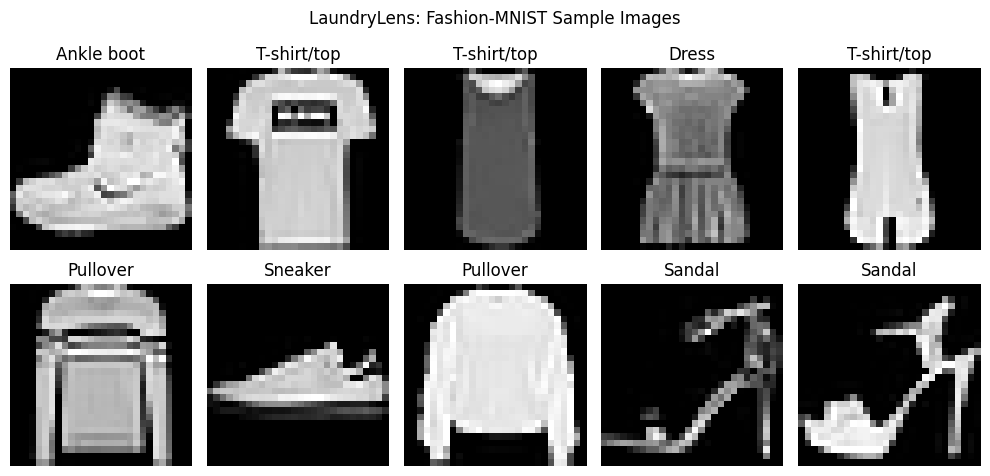

In [5]:

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.suptitle("LaundryLens: Fashion-MNIST Sample Images")
plt.tight_layout()
plt.show()


In [6]:
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Add the grayscale channel dimension
X_train = X_train[..., np.newaxis]
X_test = X_test[..., np.newaxis]

print("Processed training shape:", X_train.shape)
print("Processed testing shape:", X_test.shape)
print("Pixel value range:", X_train.min(), "to", X_train.max())

Processed training shape: (60000, 28, 28, 1)
Processed testing shape: (10000, 28, 28, 1)
Pixel value range: 0.0 to 1.0


In [7]:

from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D,
    Flatten, Dense, Dropout
)

model = Sequential([
    Input(shape=(28, 28, 1)),

    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.3),

    Dense(10, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
history = model.fit(
    X_train,
    y_train,
    epochs=8,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)


Epoch 1/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 42s 96ms/step - accuracy: 0.7784 - loss: 0.6168 - val_accuracy: 0.8600 - val_loss: 0.3839
Epoch 2/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 40s 96ms/step - accuracy: 0.8631 - loss: 0.3801 - val_accuracy: 0.8762 - val_loss: 0.3277
Epoch 3/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 40s 93ms/step - accuracy: 0.8803 - loss: 0.3293 - val_accuracy: 0.8847 - val_loss: 0.3049
Epoch 4/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 42s 95ms/step - accuracy: 0.8900 - loss: 0.3015 - val_accuracy: 0.8917 - val_loss: 0.2940
Epoch 5/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 39s 93ms/step - accuracy: 0.8972 - loss: 0.2789 - val_accuracy: 0.9038 - val_loss: 0.2670
Epoch 6/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 41s 94ms/step - accuracy: 0.9060 - loss: 0.2589 - val_accuracy: 0.9043 - val_loss: 0.2640
Epoch 7/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 42s 95ms/step - accuracy: 0.9102 - loss: 0.2450 - val_accuracy: 0.9025 - val_loss: 0.2657
Epoch 8/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 40s 94ms/step - accuracy: 0.9163 - loss: 0.2296 - val_accu

In [9]:
test_loss, test_accuracy = model.evaluate(
    X_test, y_test, verbose=0
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")


Test Loss: 0.2570
Test Accuracy: 90.57%


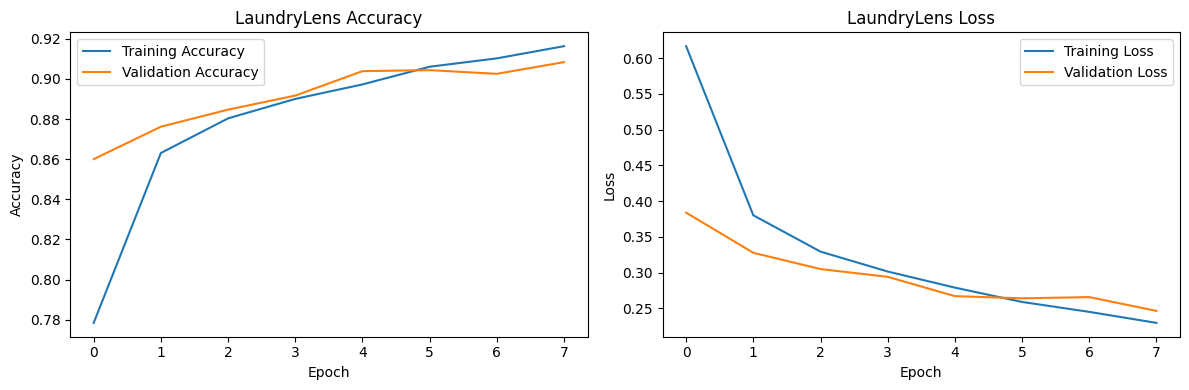

In [10]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("LaundryLens Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("LaundryLens Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


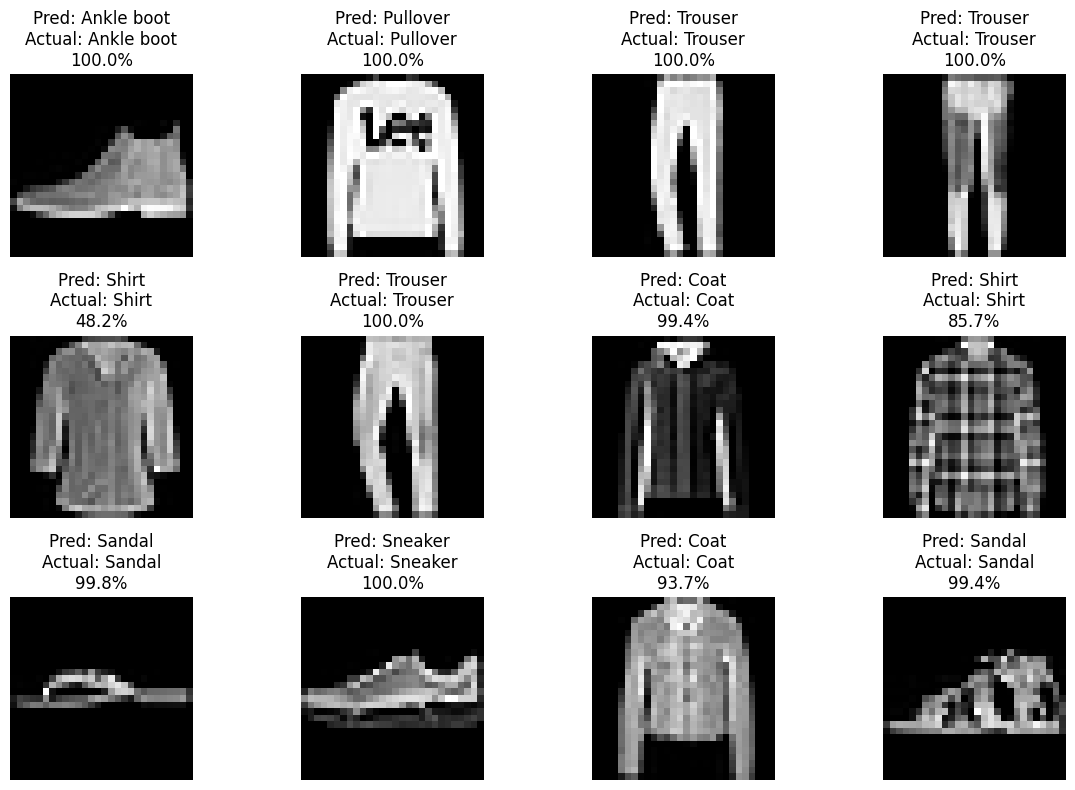

In [11]:
predictions = model.predict(X_test[:12], verbose=0)

plt.figure(figsize=(12, 8))

for i in range(12):
    predicted_class = np.argmax(predictions[i])
    confidence = np.max(predictions[i]) * 100

    plt.subplot(3, 4, i + 1)
    plt.imshow(X_test[i].squeeze(), cmap="gray")

    actual = class_names[y_test[i]]
    predicted = class_names[predicted_class]

    plt.title(
        f"Pred: {predicted}\nActual: {actual}\n{confidence:.1f}%"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()


In [12]:
model.save("laundrylens_model.keras")

print("LaundryLens model saved successfully!")


LaundryLens model saved successfully!


In [13]:

from sklearn.metrics import classification_report

y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)

print(classification_report(
    y_test,
    y_pred,
    target_names=class_names
))


              precision    recall  f1-score   support

 T-shirt/top       0.84      0.88      0.86      1000
     Trouser       0.99      0.98      0.99      1000
    Pullover       0.79      0.91      0.85      1000
       Dress       0.88      0.94      0.91      1000
        Coat       0.87      0.82      0.84      1000
      Sandal       0.98      0.98      0.98      1000
       Shirt       0.81      0.64      0.71      1000
     Sneaker       0.96      0.95      0.96      1000
         Bag       0.98      0.98      0.98      1000
  Ankle boot       0.96      0.97      0.96      1000

    accuracy                           0.91     10000
   macro avg       0.91      0.91      0.90     10000
weighted avg       0.91      0.91      0.90     10000



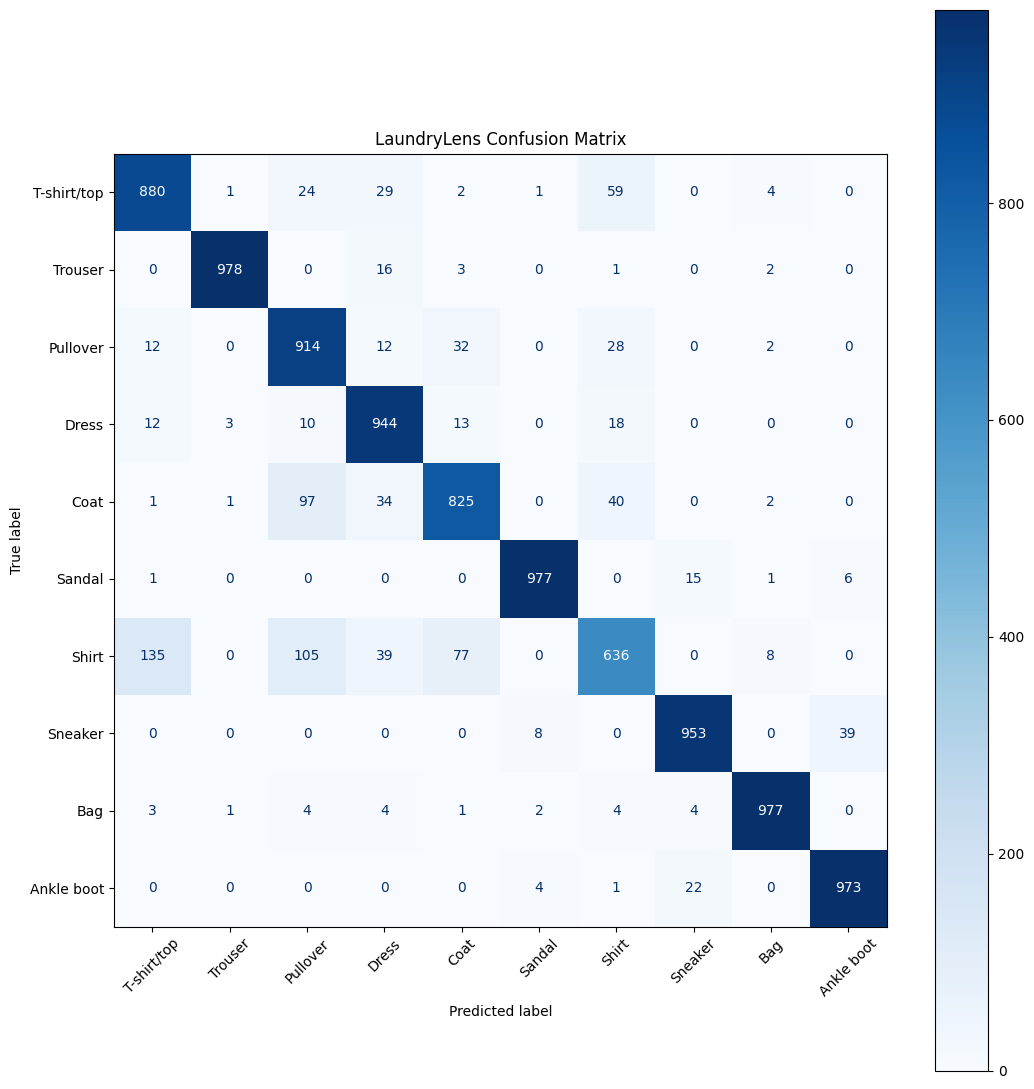

In [14]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(11, 11))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45)
plt.title("LaundryLens Confusion Matrix")
plt.tight_layout()
plt.show()
